# Learning Disruption Cascades in Product-Integrated Supply Networks
**INCOM 2027 — experiment notebook**

This notebook runs the full study we agreed on, in four stages, each ending in a **gate**:

| Stage | What it does | Gate |
|---|---|---|
| 1 · Network generation | Product-integrated, multi-tier (depth 8) firm networks: multi-level BOM → firms → sourcing, with **controlled triads** (shared supplier, co-suppliers, transitive triangle, diamond, shared material) | structure is valid, controllable and realistic |
| 2 · Discrete-event simulation | Continuous-time DES of every firm (orders, AND-BOM production, FCFS shipping, base-stock replenishment, rerouting) | validation checks pass |
| 3 · Disruption & cascade paths | Firm outages; per-firm ground truth (hit, direction, time-to-impact, severity, **causal parent**) | cascades are non-trivial (rules miss them) |
| 4 · GNN | AND/OR-aware GNN vs rules and baselines, on unseen and larger networks | — |

**Hypotheses**
- **H1 — structure shapes cascades:** lateral and upstream cascades travel through shared suppliers and co-suppliers; tight capacity amplifies them; **diamonds cancel the protection of dual sourcing**.
- **H2 — topology is not enough:** topology/buffer cascade rules (reachability, Zhao-style) miss a substantial share of cascades — mainly lateral/upstream hits and timing.
- **H3 — a GNN learns cascades:** a product-aware (AND/OR) GNN predicts who is hit and when on unseen networks, beating rules and a generic GNN, most of all on far-hop and triad-driven cascades.

**Run modes.** `MODE = "quick"` runs everything end-to-end in minutes (small networks, few disruptions) — use it to check the pipeline. `MODE = "incom"` is the paper-scale run (≈600 networks); run it on a multi-core machine.

*Research code. It lives in `scsim/scripts/research/ripple/` and does not modify the scsim engine.*

In [1]:
import copy, heapq, math, time, os, random, warnings
from collections import defaultdict, deque
from dataclasses import dataclass, asdict
import multiprocessing as mp

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160, "display.max_columns", 30)

MODE = os.environ.get("RIPPLE_MODE", "quick")   # "quick" | "incom"

CONFIGS = {
    "quick": dict(nets_per_family=8, big_nets_per_family=3, scale=0.5, big_scale=1.0,
                  targets_per_tier=2, durations=[21, 56], horizon=160, warmup=120,
                  null_samples=10, epochs=25, hidden=64, workers=min(4, os.cpu_count() or 1)),
    "incom": dict(nets_per_family=200, big_nets_per_family=30, scale=1.0, big_scale=2.0,
                  targets_per_tier=4, durations=[14, 28, 56, 84], horizon=240, warmup=150,
                  null_samples=20, epochs=80, hidden=96, workers=os.cpu_count() or 1),
}
CFG = CONFIGS[MODE]
SEED = 2027
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
print("MODE =", MODE, CFG)

MODE = quick {'nets_per_family': 8, 'big_nets_per_family': 3, 'scale': 0.5, 'big_scale': 1.0, 'targets_per_tier': 2, 'durations': [21, 56], 'horizon': 160, 'warmup': 120, 'null_samples': 10, 'epochs': 25, 'hidden': 64, 'workers': 4}


## Stage 1 · Product-integrated network generation

**Two linked graphs.** The *item graph* is a multi-level BOM over item tiers 0–8 (end products at tier 0, raw materials at tier 8). The *firm graph* says who makes each item and who buys from whom. **Every node is a firm**; market demand enters at the tier-0 firms (OEMs) and is not a node.

**Logic.**
- **AND** — an item can be produced only when *all* its BOM components are on hand.
- **OR** — a component can come from alternative producers (multi-sourcing).
- **Shared capacity** — multi-product firms run all their items on one resource.

**Generation pipeline** (`generate_structure`), each step with its own control:

| Step | Mechanism | Control | Triad it creates |
|---|---|---|---|
| 1 BOM | items per tier from the family template; components chosen with preferential attachment on use, biased to the same product platform | `m`, `alpha_bom`, `mix` | **shared material** (component commonality) |
| 2 Closure | if *i* uses *j* and *j* uses *l*, *i* also uses *l* directly (mixed-level BOM) | `tau` | **transitive triangle** (item level) |
| 3 Firms | firms specialise: each portfolio holds items of one platform; each item gets up to two extra producers (mostly same-platform firms) | `p`, `q` | shared capacity; alternatives; community structure |
| 4 Sourcing | per (buyer, component): a co-source copies its sibling's supplier with prob. κ (else diversifies away from it); else copy a peer's supplier (β); else preferential attachment (α); second source with prob. ρ | `alpha`, `beta`, `rho`, `kappa` | **shared supplier**, **co-suppliers**, **diamond** |
| 5 Directed sourcing | a closure component is bought from the firm that supplies it to the buyer's own suppliers | `tau_d` | **transitive triangle** (firm level) |
| 6 Quantities | MRP explosion of market demand → item rates → component needs → capacity from target utilisation `u`; lead times; base stock = need × (lead time + order cycle + supplier lot cycle + safety days) | `u`, `comp_safety`, `fg_safety` | — |

Edges only go one tier down (closure: two), so the **longest firm path is exactly 8** by construction — checked below.

In [2]:
N_TIERS = 9            # firm/item tiers T0 (OEM) … T8 (raw material) -> depth 8
LOT_DAYS = 7.0         # production lot = 7 days of the item's rate
ORDER_DAYS = 7.0       # replenishment order = 7 days of the component's need

FAMILIES = {
    # items per tier T0..T8, BOM size m, use-preference, cross-platform mixing, firm portfolio p,
    # q = probability of each of up to two extra producers per item, plat = number of product platforms
    "pyramid":    dict(items=[8, 14, 20, 26, 32, 38, 44, 50, 56], m=(2, 4), alpha_bom=1.0, mix=0.15, p=(1, 2), q=0.35, plat=4, fixed={}),
    "assembly":   dict(items=[6, 14, 24, 34, 42, 48, 52, 54, 56], m=(3, 6), alpha_bom=1.5, mix=0.10, p=(1, 3), q=0.30, plat=3, fixed={}),
    "chokepoint": dict(items=[8, 14, 20, 26,  3, 30, 36, 42, 48], m=(2, 3), alpha_bom=1.0, mix=0.15, p=(1, 2), q=0.30, plat=4, fixed={4: 3}),
}

# Network-level factors, sampled by Latin hypercube within each family
FACTORS = dict(u=(0.60, 0.92), rho=(0.0, 0.8), alpha=(0.0, 1.5), beta=(0.0, 0.8), kappa=(0.0, 0.9),
               tau=(0.0, 0.06), tau_d=(0.0, 0.8), comp_safety=(1.0, 8.0), fg_safety=(1.0, 5.0), delta=(1.0, 10.0))


def latin_hypercube(n, ranges, rng):
    keys = list(ranges)
    out = [dict() for _ in range(n)]
    for k in keys:
        lo, hi = ranges[k]
        strata = (rng.permutation(n) + rng.random(n)) / n
        for r in range(n):
            out[r][k] = float(lo + strata[r] * (hi - lo))
    return out


def generate_structure(fp):
    """Steps 1-5: item BOM, firms and sourcing. Returns the raw structure (no quantities)."""
    fam = FAMILIES[fp["family"]]
    rng = np.random.default_rng(fp["seed"])
    widths = [max(2, int(round(w * fp["scale"]))) for w in fam["items"]]
    for k, w in fam["fixed"].items():
        widths[k] = w
    starts = np.cumsum([0] + widths)
    tier_items = [list(range(starts[k], starts[k + 1])) for k in range(N_TIERS)]
    item_tier = np.concatenate([[k] * w for k, w in enumerate(widths)]).astype(int)
    n_items = len(item_tier)

    # --- 1. BOM with platforms (product families) and component commonality
    n_plat = min(fam["plat"], widths[0])
    item_plat = rng.integers(0, n_plat, n_items)
    item_plat[tier_items[0]] = np.arange(widths[0]) % n_plat
    uses = np.zeros(n_items)
    bom = [dict() for _ in range(n_items)]
    for k in range(N_TIERS - 1):
        cand = np.array(tier_items[k + 1])
        for i in tier_items[k]:
            m = int(min(rng.integers(fam["m"][0], fam["m"][1] + 1), len(cand)))
            w = (uses[cand] + 1.0) ** fam["alpha_bom"] * np.where(item_plat[cand] == item_plat[i], 1.0, fam["mix"])
            for c in rng.choice(cand, size=m, replace=False, p=w / w.sum()):
                bom[i][int(c)] = int(rng.integers(1, 4)); uses[c] += 1
    for k in range(1, N_TIERS):                       # every non-end item has a parent
        for j in tier_items[k]:
            if uses[j] == 0:
                par = [i for i in tier_items[k - 1] if item_plat[i] == item_plat[j]] or tier_items[k - 1]
                bom[int(rng.choice(par))][j] = int(rng.integers(1, 4)); uses[j] += 1

    # --- 2. triadic closure on the BOM (mixed-level components)
    closure = set()
    for k in range(N_TIERS - 2):
        for i in tier_items[k]:
            for j in [c for c in list(bom[i]) if item_tier[c] == k + 1]:
                for l in [c for c in bom[j] if item_tier[c] == k + 2]:
                    if l not in bom[i] and rng.random() < fp["tau"]:
                        bom[i][l] = 1; closure.add((i, l)); uses[l] += 1

    # --- 3. firms: specialised portfolios (items of one platform) + extra producers (alternatives)
    firm_tier, firm_items, firm_plat = [], [], []
    producers = [[] for _ in range(n_items)]
    for k in range(N_TIERS):
        first = len(firm_tier)
        for pl in rng.permutation(n_plat):
            its = [int(v) for v in rng.permutation([i for i in tier_items[k] if item_plat[i] == pl])]
            while its:
                p = int(rng.integers(fam["p"][0], fam["p"][1] + 1))
                f = len(firm_tier); firm_tier.append(k); firm_items.append(its[:p]); firm_plat.append(int(pl))
                for i in its[:p]:
                    producers[i].append(f)
                its = its[p:]
        tf = list(range(first, len(firm_tier)))
        for i in tier_items[k]:                      # up to two extra producers, mostly from the same platform
            for _ in range(2):
                cand = [f for f in tf if f not in producers[i]]
                same = [f for f in cand if firm_plat[f] == item_plat[i]]
                if cand and rng.random() < fam["q"]:
                    f2 = int(rng.choice(same if same and rng.random() < 0.8 else cand))
                    producers[i].append(f2); firm_items[f2].append(i)
    n_firms = len(firm_tier)
    tier_firms = [[f for f in range(n_firms) if firm_tier[f] == k] for k in range(N_TIERS)]

    # --- 4. sourcing (regular components, top-down so co-source relations exist before they are copied)
    sources = {}                       # (buyer firm, component item) -> [supplier firms]
    n_buyers = defaultdict(int)
    cosrc = defaultdict(set)           # firms that are co-sources (alternatives) for some buyer
    comp_choice = defaultdict(list)    # component -> first sources already chosen by other buyers
    suppliers_of = defaultdict(set)

    def pa_pick(cands, exclude=()):
        cands = [s for s in cands if s not in exclude]
        w = np.array([(n_buyers[s] + 1.0) ** fp["alpha"] for s in cands])
        return int(rng.choice(cands, p=w / w.sum()))

    def comps(f, regular):
        k = firm_tier[f]
        return sorted({c for i in firm_items[f] for c in bom[i] if (item_tier[c] == k + 1) == regular})

    for k in range(N_TIERS - 1):
        for f in [int(v) for v in rng.permutation(tier_firms[k])]:
            for c in comps(f, True):
                prods, first, avoid = producers[c], None, set()
                sib = {s for g in cosrc[f] if (g, c) in sources for s in sources[(g, c)]}   # co-sources' suppliers of c
                if sib:
                    if rng.random() < fp["kappa"]:                                 # diamond: copy the sibling's supplier
                        first = int(rng.choice(sorted(sib)))
                    elif set(prods) - sib:                                         # else diversify away from it
                        avoid = sib
                if first is None and comp_choice[c] and rng.random() < fp["beta"]:  # shared supplier: copy peers' favourite
                    opts = [s for s in comp_choice[c] if s not in avoid]
                    if opts:
                        first = int(max(set(opts), key=opts.count))
                if first is None:
                    first = pa_pick(prods, exclude=avoid)                          # hubs
                srcs = [first]
                if len(prods) >= 2 and rng.random() < fp["rho"]:                   # dual sourcing
                    srcs.append(pa_pick(prods, exclude=srcs))
                sources[(f, c)] = srcs
                comp_choice[c].append(first)
                for s in srcs:
                    n_buyers[s] += 1; suppliers_of[f].add(s)
        # every producer of a tier-(k+1) item serves at least one buyer (positive flow everywhere);
        # done before tier k+1 sources, so the co-source relations it creates are known when they choose
        for c in tier_items[k + 1]:
            grp = [(f, c) for f in tier_firms[k] if (f, c) in sources]
            used = {s for g in grp for s in sources[g]}
            for s in producers[c]:
                if s not in used:
                    g = grp[int(rng.integers(len(grp)))]
                    sources[g].append(s); used.add(s); n_buyers[s] += 1; suppliers_of[g[0]].add(s)
            for g in grp:
                for a in sources[g]:
                    cosrc[a].update(b for b in sources[g] if b != a)

    # --- 5. closure components: directed sourcing
    for f in range(n_firms):
        for c in comps(f, False):
            first = None
            if rng.random() < fp["tau_d"]:
                D = sorted({s2 for s in suppliers_of[f] if (s, c) in sources for s2 in sources[(s, c)]})
                if D:
                    first = int(rng.choice(D))
            if first is None:
                first = pa_pick(producers[c])
            sources[(f, c)] = [first]; n_buyers[first] += 1

    # every producer of every item serves at least one buyer of it -> positive flow everywhere
    groups_of_item = defaultdict(list)
    for (f, c) in sources:
        groups_of_item[c].append((f, c))
    for c in range(n_items):
        if item_tier[c] == 0:
            continue
        used = {s for g in groups_of_item[c] for s in sources[g]}
        for s in producers[c]:
            if s not in used:
                g = groups_of_item[c][int(rng.integers(len(groups_of_item[c])))]
                sources[g].append(s); used.add(s)

    return dict(fp=fp, item_tier=item_tier, item_plat=item_plat, bom=bom, closure=closure, firm_plat=firm_plat,
                firm_tier=firm_tier, firm_items=firm_items, producers=producers, sources=sources)


def build_net(st, seed=0):
    """Step 6: quantities, capacities, lead times, stock levels; index everything for the DES."""
    fp, rng = st["fp"], np.random.default_rng(seed + 7)
    firm_tier, firm_items, bom, sources = st["firm_tier"], st["firm_items"], st["bom"], st["sources"]
    n_firms = len(firm_tier)
    # MRP explosion (tier by tier, top-down)
    x = defaultdict(float)
    for f in range(n_firms):
        if firm_tier[f] == 0:
            for i in firm_items[f]:
                d = st.get("demand", {}).get(i, None)
                if d is None:
                    d = float(np.random.default_rng(seed * 1000 + i).uniform(5, 20))
                x[(f, i)] += d / len(st["producers"][i])
    need = defaultdict(float)
    for k in range(N_TIERS):
        for f in [f for f in range(n_firms) if firm_tier[f] == k]:
            for i in firm_items[f]:
                for c, a in bom[i].items():
                    need[(f, c)] += x[(f, i)] * a
        for (f, c), srcs in sources.items():
            if firm_tier[f] == k:
                for s in srcs:
                    x[(s, c)] += need[(f, c)] / len(srcs)
    pairs = [(f, i) for f in range(n_firms) for i in firm_items[f] if x[(f, i)] > 1e-9]
    groups = [g for g in sorted(sources, key=lambda g: (firm_tier[g[0]], g[0], g[1])) if need[g] > 1e-9]
    gidx = {g: n for n, g in enumerate(groups)}
    edges = sorted({(s, f) for (f, c) in groups for s in sources[(f, c)]})
    eidx = {e: n for n, e in enumerate(edges)}
    lead = {e: float(rng.integers(2, 4 + firm_tier[e[0]])) for e in edges}       # days, longer upstream
    thru = np.zeros(n_firms)
    for (f, i) in pairs:
        thru[f] += x[(f, i)]
    u_f = np.clip(fp["u"] + rng.uniform(-0.05, 0.05, n_firms), 0.3, 0.97)
    cap = thru / u_f                                                              # units/day, shared by items
    spread = (0.0, 0.0) if fp.get("exact_buffers") else (0.5, 1.5)        # firm-level heterogeneity
    comp_safety = fp["comp_safety"] * (rng.uniform(*spread, n_firms) if spread[1] else np.ones(n_firms))
    fg_safety = fp["fg_safety"] * (rng.uniform(*spread, n_firms) if spread[1] else np.ones(n_firms))
    g_src = [list(sources[g]) for g in groups]
    g_need = np.array([need[g] for g in groups])
    g_L = np.array([max(lead[(s, g[0])] for s in sources[g]) for g in groups])
    # base stock covers lead time + own order cycle + the supplier's lot cycle + safety days
    g_S = np.array([need[g] * (g_L[n] + ORDER_DAYS + LOT_DAYS + comp_safety[g[0]]) for n, g in enumerate(groups)])
    g_Q = g_need * ORDER_DAYS
    req = {(f, i): [(gidx[(f, c)], a) for c, a in bom[i].items()] for (f, i) in pairs}
    items_of = defaultdict(list)
    for (f, i) in pairs:
        items_of[f].append(i)
    xr = {p: x[p] for p in pairs}
    fgS = {(f, i): x[(f, i)] * (LOT_DAYS + fg_safety[f]) for (f, i) in pairs}
    lotQ = {(f, i): x[(f, i)] * LOT_DAYS for (f, i) in pairs}
    groups_of_firm = defaultdict(list)
    for n, (f, c) in enumerate(groups):
        groups_of_firm[f].append(n)
    G = nx.DiGraph()
    G.add_nodes_from(range(n_firms))
    G.add_edges_from(edges)
    return dict(st=st, fp=fp, n_firms=n_firms, firm_tier=np.array(firm_tier), items_of=dict(items_of), pairs=pairs,
                x=xr, fgS=fgS, lotQ=lotQ, req=req, groups=groups, gidx=gidx, g_src=g_src, g_need=g_need, g_L=g_L,
                g_S=g_S, g_Q=g_Q, edges=edges, eidx=eidx, lead=lead, thru=thru, cap=cap, u_f=u_f,
                comp_safety=comp_safety, fg_safety=fg_safety, groups_of_firm=dict(groups_of_firm), G=G,
                closure_groups={gidx[(f, c)] for (f, c) in groups
                                if st["item_tier"][c] == firm_tier[f] + 2})


def check_structure(net):
    """Gate-1 structural checks. Raises if the network is invalid."""
    G, ft = net["G"], net["firm_tier"]
    assert nx.is_directed_acyclic_graph(G), "firm graph has a cycle"
    depth = nx.dag_longest_path_length(G)
    assert depth == N_TIERS - 1, f"depth {depth} != 8"
    raw, oem = [f for f in G if ft[f] == N_TIERS - 1], [f for f in G if ft[f] == 0]
    reach_down = set().union(*[nx.descendants(G, r) | {r} for r in raw])
    reach_up = set().union(*[nx.ancestors(G, o) | {o} for o in oem])
    assert len(reach_down) == len(G) and len(reach_up) == len(G), "a firm is not on a raw->OEM path"
    return depth


def make_network(fp):
    st = generate_structure(fp)
    net = build_net(st, seed=fp["seed"])
    check_structure(net)
    return net

### Fingerprint, triad census and realism
For every network we compute a **fingerprint**: size, degree statistics, assortativity, Collier's **degree of commonality** (DCI), the **hidden-concentration ratio** (for dual-sourced components: share of their inputs — among inputs that have alternative producers — that both sources buy from the same firm, i.e. diamonds), **producer dominance** (share of a component's buyers held by its most popular producer), **shared-supplier pairs** (share of same-tier firms that share a supplier), **platform modularity** (community structure along product platforms), shared-supplier and co-supplier counts, and the **triad census** of the firm graph with **z-scores against a tier-preserving random null** (same number of links between every pair of tiers, placed at random). Positive z = more of that triad than chance. Triad codes (supplier → buyer): `021D` shared supplier, `021U` co-suppliers, `021C` chain, `030T` transitive triangle.

In [3]:
TRIADS = {"021D": "shared supplier", "021U": "co-suppliers", "021C": "chain", "030T": "transitive triangle"}


def null_graph(G, tiers, rng):
    """Tier-preserving random graph: same number of links between every pair of tiers, placed at random
    (firm degrees are NOT preserved, so concentration created by hubs/copying/commonality shows up in the z-score)."""
    H = nx.DiGraph(); H.add_nodes_from(G)
    by_tier = defaultdict(list)
    for f in G:
        by_tier[tiers[f]].append(f)
    count = defaultdict(int)
    for (s, b) in G.edges:
        count[(tiers[s], tiers[b])] += 1
    for (ts, tb), m in count.items():
        S, B = by_tier[ts], by_tier[tb]
        cells = rng.choice(len(S) * len(B), size=min(m, len(S) * len(B)), replace=False)
        H.add_edges_from((S[c // len(B)], B[c % len(B)]) for c in cells)
    return H


def fingerprint(net, null_samples=0, rng=None):
    G, st = net["G"], net["st"]
    item_tier, bom = st["item_tier"], st["bom"]
    parents = defaultdict(int)
    for i, comps_ in enumerate(bom):
        for c in comps_:
            parents[c] += 1
    dci = np.mean([parents[c] for c in range(len(item_tier)) if item_tier[c] > 0])
    sources = st["sources"]
    dual = [n for n, s in enumerate(net["g_src"]) if len(s) >= 2]
    diam = elig = 0     # (dual-sourced group, input with >= 2 producers): do the two sources buy that input from the same firm?
    for n in dual:
        c, srcs = net["groups"][n][1], net["g_src"][n]
        for l in bom[c]:
            sets = [set(sources.get((b, l), [])) for b in srcs]
            if all(sets) and len(st["producers"][l]) >= 2:
                elig += 1
                diam += bool(set.intersection(*sets))
    dom = []                                   # producer dominance: share of a component's buyers held by its top producer
    for c, prods in enumerate(st["producers"]):
        if len(prods) >= 2:
            cnt = np.array([sum(p in srcs for (b, cc), srcs in sources.items() if cc == c) for p in prods], float)
            if cnt.sum() >= 3:
                dom.append(cnt.max() / cnt.sum())
    ft = net["firm_tier"]
    shared = []                                # share of same-tier buyer pairs that share at least one supplier
    for k in range(N_TIERS - 1):
        fs = [f for f in G if ft[f] == k]
        pre = {f: set(G.predecessors(f)) for f in fs}
        pr = [(a, b) for n_, a in enumerate(fs) for b in fs[n_ + 1:]]
        if pr:
            shared.append(np.mean([bool(pre[a] & pre[b]) for a, b in pr]))
    comms = defaultdict(set)
    for f, pl in enumerate(st["firm_plat"]):
        comms[pl].add(f)
    modularity = nx.algorithms.community.modularity(G.to_undirected(), list(comms.values()))
    outdeg = np.array([d for _, d in G.out_degree()])
    indeg = np.array([d for _, d in G.in_degree()])
    fpd = dict(family=net["fp"]["family"], firms=G.number_of_nodes(), edges=G.number_of_edges(),
               depth=nx.dag_longest_path_length(G), items=len(item_tier),
               mean_out=outdeg.mean(), max_out=outdeg.max(), mean_in=indeg.mean(),
               assort=nx.degree_pearson_correlation_coefficient(G.to_undirected()) if G.number_of_edges() > 3 else np.nan,
               dci=dci, dual_share=len(dual) / max(1, len(net["g_src"])), producer_dominance=np.mean(dom) if dom else np.nan,
               shared_supplier_pairs=np.mean(shared), platform_modularity=modularity,
               hidden_conc=diam / max(1, elig), closure_groups=len(net["closure_groups"]))
    census = nx.triadic_census(G)
    for code in TRIADS:
        fpd[f"n_{code}"] = census[code]
    if null_samples:
        tiers = net["firm_tier"]
        null = {code: [] for code in TRIADS}
        for _ in range(null_samples):
            cs = nx.triadic_census(null_graph(G, tiers, rng))
            for code in TRIADS:
                null[code].append(cs[code])
        for code in TRIADS:
            mu, sd = np.mean(null[code]), np.std(null[code])
            fpd[f"z_{code}"] = (census[code] - mu) / sd if sd > 0 else np.nan
    return fpd

### Generate the network sets
Three families (pyramid, complex assembly, chokepoint). Each family gets `nets_per_family` training-scale networks (split into train/val/test by network) plus `big_nets_per_family` **larger** networks used only for the size-generalisation test.

In [4]:
def network_specs():
    rng = np.random.default_rng(SEED)
    specs = []
    for fam in FAMILIES:
        n_small, n_big = CFG["nets_per_family"], CFG["big_nets_per_family"]
        lhs = latin_hypercube(n_small + n_big, FACTORS, rng)
        split = rng.permutation(n_small)
        n_tr, n_va = int(round(0.7 * n_small)), max(1, int(round(0.15 * n_small)))
        for r, f in enumerate(lhs):
            big = r >= n_small
            if big:
                sp = "big"
            else:
                pos = int(np.where(split == r)[0][0])
                sp = "train" if pos < n_tr else ("val" if pos < n_tr + n_va else "test")
            specs.append(dict(f, family=fam, seed=int(rng.integers(1e9)),
                              scale=CFG["big_scale"] if big else CFG["scale"], split=sp))
    return specs


t0 = time.time()
SPECS = network_specs()
NETS = []
for k, fp in enumerate(SPECS):
    for attempt in range(5):
        try:
            NETS.append(make_network(fp)); break
        except AssertionError as e:
            fp["seed"] += 1
    else:
        raise RuntimeError(f"could not build network {k}")
print(f"{len(NETS)} networks built and checked (depth 8, DAG, every firm on a raw->OEM path) in {time.time()-t0:.1f}s")

rng_fp = np.random.default_rng(SEED + 1)
atlas_ids = [next(n for n, s in enumerate(SPECS) if s["family"] == fam and s["split"] == "train") for fam in FAMILIES]
FP = pd.DataFrame([dict(fingerprint(net, CFG["null_samples"] if n in atlas_ids else 0, rng_fp), split=SPECS[n]["split"], net=n)
                   for n, net in enumerate(NETS)])
summary = FP.groupby("family")[["firms", "edges", "depth", "mean_out", "max_out", "assort", "dci", "platform_modularity",
                                "shared_supplier_pairs", "dual_share", "producer_dominance", "hidden_conc", "n_030T"]].mean().round(2)
summary

33 networks built and checked (depth 8, DAG, every firm on a raw->OEM path) in 1.4s


,firms,edges,depth,mean_out,max_out,assort,dci,platform_modularity,shared_supplier_pairs,dual_share,producer_dominance,hidden_conc,n_030T
family,,,,,,,,,,,,,
assembly,114.91,851.64,8.0,7.12,22.18,-0.00,4.43,0.19,0.99,0.20,0.59,0.74,697.64
chokepoint,103.45,467.09,8.0,4.32,15.73,-0.16,2.56,0.20,0.92,0.23,0.59,0.72,143.82
pyramid,130.18,733.73,8.0,5.49,16.00,-0.01,2.89,0.21,0.94,0.25,0.58,0.72,205.45


In [5]:
print("Triad z-scores vs a tier-preserving random null (one atlas network per family):")
FP.loc[atlas_ids, ["family", "firms", "z_021D", "z_021U", "z_021C", "z_030T"]].round(2)

Triad z-scores vs a tier-preserving random null (one atlas network per family):


,family,firms,z_021D,z_021U,z_021C,z_030T
0,pyramid,101,9.99,0.92,5.63,10.66
11,assembly,94,7.78,-3.62,2.13,12.67
23,chokepoint,84,5.71,-2.03,-1.80,11.00


**Controls respond as intended?** (Gate 1.) The sampled factors should move the structural indices they control — κ → hidden concentration (diamonds), β/α → producer dominance, ρ → dual-sourcing share, τ → closure (tier-skipping) groups. Spearman correlations across all networks:

In [6]:
ctrl = pd.DataFrame([dict(kappa=s["kappa"], beta=s["beta"], alpha=s["alpha"], rho=s["rho"], tau=s["tau"],
                          tau_d=s["tau_d"]) for s in SPECS])
chk = pd.concat([ctrl, FP[["hidden_conc", "producer_dominance", "dual_share", "n_030T", "closure_groups"]]], axis=1)
gate1 = pd.DataFrame({
    "kappa -> hidden_conc": [chk["kappa"].corr(chk["hidden_conc"], method="spearman")],
    "beta -> producer_dominance": [chk["beta"].corr(chk["producer_dominance"], method="spearman")],
    "alpha -> producer_dominance": [chk["alpha"].corr(chk["producer_dominance"], method="spearman")],
    "rho -> dual_share": [chk["rho"].corr(chk["dual_share"], method="spearman")],
    "tau -> closure_groups": [chk["tau"].corr(chk["closure_groups"], method="spearman")],
}).round(2)
gate1

,kappa -> hidden_conc,beta -> producer_dominance,alpha -> producer_dominance,rho -> dual_share,tau -> closure_groups
0,0.41,0.35,0.1,0.93,0.75


**Network atlas** — one network per family, laid out by tier (raw materials left, OEMs right). Node size = throughput; red edges = closure (tier-skipping) sourcing.

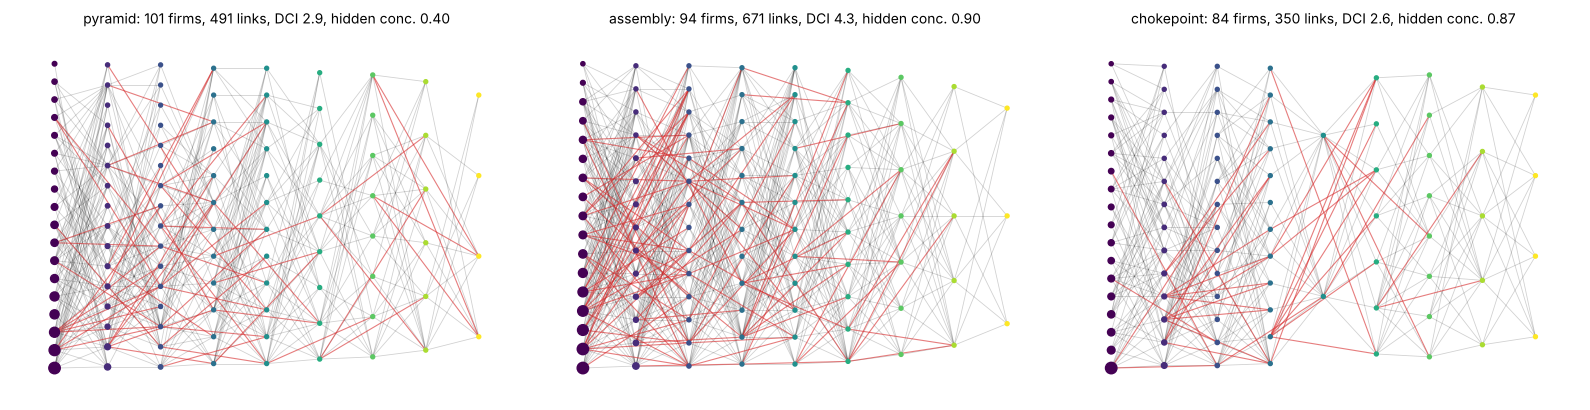

In [7]:
def draw_network(net, ax, title):
    G, ft = net["G"], net["firm_tier"]
    pos = {}
    for k in range(N_TIERS):
        fs = [f for f in G if ft[f] == k]
        for r, f in enumerate(sorted(fs, key=lambda f: -net["thru"][f])):
            pos[f] = (N_TIERS - 1 - k, (r - (len(fs) - 1) / 2) / max(1, len(fs)))
    skip = [(s, b) for (s, b) in G.edges if ft[s] - ft[b] == 2]
    norm = [(s, b) for (s, b) in G.edges if ft[s] - ft[b] == 1]
    nx.draw_networkx_edges(G, pos, edgelist=norm, ax=ax, alpha=0.18, arrows=False, width=0.6)
    nx.draw_networkx_edges(G, pos, edgelist=skip, ax=ax, alpha=0.6, arrows=False, width=0.8, edge_color="tab:red")
    sz = 8 + 60 * net["thru"] / net["thru"].max()
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=sz, node_color=[ft[f] for f in G], cmap="viridis_r")
    ax.set_title(title, fontsize=10); ax.set_xticks(range(N_TIERS)); ax.set_xticklabels([f"T{N_TIERS-1-k}" for k in range(N_TIERS)])
    ax.tick_params(left=False, labelleft=False); ax.set_frame_on(False)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, n in zip(axes, atlas_ids):
    r = FP.loc[n]
    draw_network(NETS[n], ax, f"{r.family}: {r.firms} firms, {r.edges} links, DCI {r.dci:.1f}, hidden conc. {r.hidden_conc:.2f}")
plt.tight_layout(); plt.show()

## Stage 2 · Discrete-event simulation

Continuous time (days), one event list. **Entities:** market orders, replenishment orders, production lots, shipments. **The same firm logic at every tier:**

| Event / call | Logic |
|---|---|
| `MARKET` (tier-0 firms) | a market order of one day's demand joins the item's FCFS queue |
| `order_arrive` | a buyer's replenishment order joins the supplier's FCFS queue for that item |
| `try_ship` | while finished goods cover the head-of-queue order, ship it; it arrives after the lane lead time |
| `try_produce` | if the resource is up and idle: among items whose FG position (FG + WIP − backlog) is below target, start a lot of the one with the largest gap **for which every BOM component is on hand (AND)**; consume components |
| `check_reorder` | if a component's inventory position < base stock, order a lot from the next active source in rotation (**OR**) |
| `ARRIVAL` | component stock up; try to produce |
| `DISRUPT_START/END` | the target's resource goes down / up (*production stop*: it still ships from stock; *full stop*: shipping stops too) |
| `EXCLUDE/INCLUDE` | after the detection lag δ, buyers stop/resume ordering from the disrupted firm when they have an alternative (rerouting); the alternative's capacity is not increased |

The model is **deterministic** (constant demand, fixed lead and processing times), so one run per scenario is exact. Each network is **warmed up once**, snapshotted, and every disruption **branches from the snapshot**; the clean reference continues from the same snapshot.

In [8]:
EV_CTRL, EV_ARR, EV_DONE, EV_MKT, EV_SAMPLE = 0, 1, 2, 3, 9   # tie-break priority at equal times


class DES:
    def __init__(self, net):
        self.net = net
        self.t, self.heap, self.seq = 0.0, [], 0
        n = net["n_firms"]
        self.fg = {p: net["fgS"][p] for p in net["pairs"]}
        self.wip = {p: 0.0 for p in net["pairs"]}
        self.backlog = {p: 0.0 for p in net["pairs"]}
        self.queue = {p: deque() for p in net["pairs"]}
        self.onhand = list(net["g_S"])
        self.onorder = [0.0] * len(net["groups"])
        self.rr = [0] * len(net["groups"])
        self.busy, self.down, self.noship = [False] * n, [False] * n, [False] * n
        self.excluded = set()
        self.cum_ship, self.cum_in, self.cum_prod = [0.0] * n, [0.0] * n, [0.0] * n
        self.cum_deliv, self.cum_oe = [0.0] * len(net["edges"]), [0.0] * len(net["edges"])
        self.cum_gdel, self.cum_cons = [0.0] * len(net["groups"]), [0.0] * len(net["groups"])
        self.mkt_dem = self.mkt_served = self.mkt_late = 0.0
        self.rec = None
        for (f, i) in net["pairs"]:
            if net["firm_tier"][f] == 0:
                self.push(0.0, EV_MKT, ("mkt", f, i))

    def push(self, t, prio, ev):
        self.seq += 1
        heapq.heappush(self.heap, (t, prio, self.seq, ev))

    def run(self, until):
        while self.heap and self.heap[0][0] <= until:
            t, _, _, ev = heapq.heappop(self.heap)
            self.t = t
            kind = ev[0]
            if kind == "arr":
                _, g, qty, e = ev
                self.onhand[g] += qty; self.onorder[g] -= qty; self.cum_deliv[e] += qty; self.cum_gdel[g] += qty
                self.try_produce(self.net["groups"][g][0])
            elif kind == "done":
                _, f, i, q = ev
                self.busy[f] = False; self.wip[(f, i)] -= q; self.fg[(f, i)] += q; self.cum_prod[f] += q
                self.try_ship(f, i); self.try_produce(f)
            elif kind == "mkt":
                _, f, i = ev
                q = self.net["x"][(f, i)]
                self.queue[(f, i)].append((-1, q, t)); self.backlog[(f, i)] += q
                self.cum_in[f] += q; self.mkt_dem += q
                self.try_ship(f, i); self.try_produce(f)
                self.push(t + 1.0, EV_MKT, ev)
            elif kind == "start":
                _, f, full = ev
                self.down[f] = True; self.noship[f] = full
            elif kind == "end":
                _, f = ev
                self.down[f] = False; self.noship[f] = False
                for i in self.net["items_of"].get(f, []):
                    self.try_ship(f, i)
                self.try_produce(f)
            elif kind == "excl":
                self.excluded.add(ev[1])
            elif kind == "incl":
                self.excluded.discard(ev[1])
            elif kind == "sample":
                self.rec["ship"].append(list(self.cum_ship)); self.rec["in"].append(list(self.cum_in))
                self.rec["deliv"].append(list(self.cum_deliv)); self.rec["oe"].append(list(self.cum_oe))
                bl = [0.0] * self.net["n_firms"]
                for (f, i), b in self.backlog.items():
                    bl[f] += b
                self.rec["backlog"].append(bl)
                self.rec["mkt"].append((self.mkt_dem, self.mkt_served))
                self.push(t + 1.0, EV_SAMPLE, ev)
            # "noop": alignment events, nothing to do

    def try_ship(self, f, i):
        if self.noship[f]:
            return
        q, key, net = self.queue[(f, i)], (f, i), self.net
        while q and self.fg[key] >= q[0][1] - 1e-9:
            g, qty, t0 = q.popleft()
            self.fg[key] -= qty; self.backlog[key] -= qty; self.cum_ship[f] += qty
            if g < 0:
                self.mkt_served += qty; self.mkt_late += (self.t - t0) * qty
            else:
                b = net["groups"][g][0]; e = net["eidx"][(f, b)]
                self.push(self.t + net["lead"][(f, b)], EV_ARR, ("arr", g, qty, e))

    def try_produce(self, f):
        if self.busy[f] or self.down[f]:
            return
        net, best, best_gap = self.net, None, 1e-9
        for i in net["items_of"].get(f, []):
            key = (f, i)
            gap = (net["fgS"][key] - (self.fg[key] + self.wip[key] - self.backlog[key])) / net["x"][key]
            if gap > best_gap:
                Q = net["lotQ"][key]
                if all(self.onhand[g] >= a * Q - 1e-9 for g, a in net["req"][key]):   # AND over components
                    best, best_gap = i, gap
        if best is None:
            return
        key = (f, best); Q = net["lotQ"][key]
        for g, a in net["req"][key]:
            self.onhand[g] -= a * Q; self.cum_cons[g] += a * Q
        self.busy[f] = True; self.wip[key] += Q
        self.push(self.t + Q / net["cap"][f], EV_DONE, ("done", f, best, Q))
        for g, _ in net["req"][key]:
            self.check_reorder(g)

    def check_reorder(self, g):
        net = self.net
        S, Q, srcs = net["g_S"][g], net["g_Q"][g], net["g_src"][g]
        b, c = net["groups"][g]
        while self.onhand[g] + self.onorder[g] < S - 1e-9:
            act = [k for k, s in enumerate(srcs) if s not in self.excluded] or list(range(len(srcs)))
            k = act[self.rr[g] % len(act)]; self.rr[g] += 1                      # OR: rotate active sources
            s = srcs[k]
            self.onorder[g] += Q
            e = net["eidx"][(s, b)]; self.cum_oe[e] += Q; self.cum_in[s] += Q
            self.queue[(s, c)].append((g, Q, self.t)); self.backlog[(s, c)] += Q
            self.try_ship(s, c); self.try_produce(s)


def warmup(net):
    sim = DES(net)
    sim.run(CFG["warmup"])
    return sim


def branch(sim0, target=None, D=0.0, full=False, horizon=None):
    """Copy the warmed-up state and run a clean (target=None) or disrupted continuation."""
    sim = copy.deepcopy(sim0, memo={id(sim0.net): sim0.net})
    t0, H, delta = sim.t, horizon or CFG["horizon"], sim.net["fp"]["delta"]
    if target is None:                    # same number of control events -> identical tie-breaking
        for _ in range(4):
            sim.push(t0, EV_CTRL, ("noop",))
    else:
        sim.push(t0, EV_CTRL, ("start", target, full))
        sim.push(t0 + D, EV_CTRL, ("end", target))
        sim.push(t0 + delta, EV_CTRL, ("excl", target))
        sim.push(t0 + D + delta, EV_CTRL, ("incl", target))
    sim.rec = {k: [] for k in ["ship", "in", "deliv", "oe", "backlog", "mkt"]}
    sim.push(t0 + 0.5, EV_SAMPLE, ("sample",))
    sim.run(t0 + H)
    return {k: np.array(v) for k, v in sim.rec.items()}, sim

### Validation (Gate 2)
1. **Stable clean run** — market fill ≥ 99.5% and the network's total backlog (in firm-days of output) does not grow from the first to the second half of the horizon (tolerance 10% + 2 firm-days), on every network. Orders are lumpy, so individual backlogs oscillate; growth is what would signal an unstable system.
2. **Determinism** — two clean branches are identical.
3. **Zero disruption ⇒ zero effect** — a 0-day outage changes nothing.
4. **Conservation** — per firm and item, produced − shipped = Δ finished goods; per component, delivered − consumed = Δ on-hand.
5. **AND / OR micro-tests** on hand-built networks: an AND buyer stops when one single-sourced component stops; an OR buyer with a spare-capacity alternative and fast detection is protected, and the alternative feels the shifted orders.

In [9]:
def build_custom(firm_tier, firm_items, item_tier, bom, sources, demand, **fp_over):
    fp = dict(family="custom", seed=0, scale=1, u=0.7, rho=0, alpha=0, beta=0, kappa=0, tau=0, tau_d=0,
              comp_safety=3.0, fg_safety=1.0, delta=2.0, exact_buffers=True)
    fp.update(fp_over)
    producers = defaultdict(list)
    for f, its in enumerate(firm_items):
        for i in its:
            producers[i].append(f)
    st = dict(fp=fp, item_tier=np.array(item_tier), item_plat=np.zeros(len(item_tier), int), bom=bom, closure=set(),
              firm_tier=firm_tier, firm_items=firm_items, producers=producers, sources=sources, demand=demand)
    return build_net(st, seed=0)


def clean_ok(net):
    sim0 = warmup(net)
    rec, sim = branch(sim0)
    dem, served = rec["mkt"][-1, 0] - rec["mkt"][0, 0], rec["mkt"][-1, 1] - rec["mkt"][0, 1]
    bl = (rec["backlog"] / net["thru"]).sum(1)                          # network backlog, in firm-days of output
    h = len(bl) // 2                                                    # lumpy orders oscillate: compare half-horizon means
    growth = bl[h:].mean() - bl[:h].mean()
    return served / dem, growth <= 0.1 * bl[:h].mean() + 2.0, sim0


val = []
for n, net in enumerate(NETS):
    fill, stable, _ = clean_ok(net)
    val.append(dict(net=n, family=SPECS[n]["family"], clean_fill=fill, stable=stable))
VAL = pd.DataFrame(val)
print("1. clean runs: min market fill = %.4f, all stable = %s" % (VAL.clean_fill.min(), VAL.stable.all()))

net = NETS[atlas_ids[0]]; sim0 = warmup(net)
r1, _ = branch(sim0); r2, _ = branch(sim0)
print("2. determinism:", all(np.array_equal(r1[k], r2[k]) for k in r1))
tgt = int(np.flatnonzero(net["firm_tier"] == 4)[0])
r3, _ = branch(sim0, target=tgt, D=0.0)
print("3. zero-length outage changes nothing:", all(np.allclose(r1[k], r3[k]) for k in ["ship", "in", "deliv"]))

_, simc = branch(sim0)
fg_err = np.array([sum(simc.fg[(f, i)] - net["fgS"][(f, i)] for i in net["items_of"][f]) for f in range(net["n_firms"])]) \
    - (np.array(simc.cum_prod) - np.array(simc.cum_ship))
g_err = (np.array(simc.onhand) - net["g_S"]) - (np.array(simc.cum_gdel) - np.array(simc.cum_cons))
print("4. conservation: max |FG error| = %.2e, max |component-stock error| = %.2e" % (np.abs(fg_err).max(), np.abs(g_err).max()))

# AND test: OEM (firm 0) makes item 0 from items 1 and 2; firm 1 makes item 1 (single source); firm 2 makes item 2.
and_net = build_custom([0, 1, 1, 2, 2], [[0], [1], [2], [3], [4]], [0, 1, 1, 2, 2],
                       [{1: 1, 2: 1}, {3: 1}, {4: 1}, {}, {}], {(0, 1): [1], (0, 2): [2], (1, 3): [3], (2, 4): [4]}, {0: 10.0})
s0 = warmup(and_net); c, _ = branch(s0); d, _ = branch(s0, target=1, D=30)
oem_def = (c["ship"][:, 0] - d["ship"][:, 0]).max() / and_net["thru"][0]
print("5a. AND: OEM shipment deficit when one single-sourced component stops = %.1f days of output (> 0 expected)" % oem_def)

# OR test: OEM sources item 1 from firm 1 OR firm 2 (both make item 1, spare capacity), detection after 1 day.
or_net = build_custom([0, 1, 1, 2], [[0], [1], [1], [2]], [0, 1, 2], [{1: 1}, {2: 1}, {}],
                      {(0, 1): [1, 2], (1, 2): [3], (2, 2): [3]}, {0: 10.0}, u=0.45, delta=1.0, comp_safety=6.0)
s0 = warmup(or_net); c, _ = branch(s0); d, _ = branch(s0, target=1, D=30)
oem_def = (c["ship"][:, 0] - d["ship"][:, 0]).max() / or_net["thru"][0]
alt_extra = (d["in"][:, 2] - c["in"][:, 2]).max() / or_net["thru"][2]
print("5b. OR: OEM deficit = %.2f days (≈0 expected); alternative supplier receives %.1f extra days of orders (> 0 expected)"
      % (oem_def, alt_extra))

1. clean runs: min market fill = 1.0000, all stable = True


2. determinism: True
3. zero-length outage changes nothing: True


4. conservation: max |FG error| = 2.90e-05, max |component-stock error| = 5.48e-06
5a. AND: OEM shipment deficit when one single-sourced component stops = 2.0 days of output (> 0 expected)
5b. OR: OEM deficit = 0.00 days (≈0 expected); alternative supplier receives 28.0 extra days of orders (> 0 expected)


## Stage 3 · Disruption experiments and cascade paths

**Design.** For every network: `targets_per_tier` firms per tier T1–T8 (equal per tier, so long cascades are represented) × `durations` × production stop. Each disrupted run is compared with the clean continuation from the same snapshot.

**Ground-truth labels per firm.**
- **Hit = service failure** (the risk we predict) — the firm's unfilled orders exceed the clean run's by ≥ 1 day of its output for ≥ 3 consecutive days. A firm that merely receives fewer orders is *not* hit.
- **Order shock** (secondary) — orders received deviate (down *or* up) by ≥ 1 day of throughput for ≥ 3 consecutive days. This is how a disruption travels *upstream* (bullwhip) and how rerouted demand reaches alternative suppliers.
- **Time-to-impact τ** = first day of the failure window; **severity** = peak extra backlog (days of output); **duration** = days in failure.
- **Direction** — downstream (descendant of the target), upstream (ancestor) or lateral (neither).
- **Causal parent** — the supplier whose deliveries fell furthest behind before the failure (*supply-caused*), or, if none, the buyer whose orders rose most (*overload-caused*, e.g. rerouted demand). Following parents gives the **cascade tree**.

**Rule baselines (computed from the network alone).**
- **Reachability** — hit = downstream of the target; τ = lead-time distance.
- **Cascade rule (Zhao-style, AND/OR + buffers)** — a shortage wave leaves the target when its FG stock runs out; a buyer's component supply stops only when **all** its sources are hit (OR); a firm stops when **any** component stops (AND), after its component and FG buffers are consumed; the wave dies when buffers absorb the outage. It has no capacity, no rerouting load and no order effects, so by construction it cannot see lateral or upstream cascades.

In [10]:
THETA, PERSIST = 1.0, 3


def first_persistent(flag, P=PERSIST):
    """flag: (H, n) bool -> first index of a run of P Trues per column, -1 if none."""
    H, n = flag.shape
    if H < P:
        return np.full(n, -1)
    cs = np.vstack([np.zeros((1, n)), np.cumsum(flag, 0)])
    win = cs[P:] - cs[:-P]
    ok = win >= P
    idx = np.where(ok.any(0), ok.argmax(0), -1)
    return idx


def relations(net, target):
    G = net["G"]
    desc, anc = nx.descendants(G, target), nx.ancestors(G, target)
    hop = nx.single_source_shortest_path_length(G.to_undirected(as_view=True), target)
    dist_down = nx.single_source_dijkstra_path_length(G, target, weight=lambda u, v, d: net["lead"][(u, v)])
    direction = np.array(["self" if f == target else "down" if f in desc else "up" if f in anc else "lateral"
                          for f in range(net["n_firms"])])
    return direction, np.array([hop.get(f, 99) for f in range(net["n_firms"])]), dist_down


def label_run(net, clean, dis, target):
    thru = net["thru"]
    bl_dev = (dis["backlog"] - clean["backlog"]) / thru            # extra unfilled orders, days of output
    in_dev = (clean["in"] - dis["in"]) / thru                      # orders received: shortfall (+) / surplus (-)
    svc_i = first_persistent(bl_dev >= THETA)                     # service failure
    shk_i = first_persistent(np.abs(in_dev) >= THETA)             # order shock
    hit, shock = svc_i >= 0, shk_i >= 0
    tau = np.where(hit, svc_i, -1).astype(float); tau[~hit] = np.nan
    tau_shock = np.where(shock, shk_i, -1).astype(float); tau_shock[~shock] = np.nan
    sev = np.clip(bl_dev.max(0), 0, None)
    duration = (bl_dev >= THETA).sum(0)
    # causal parent of a service failure: the supplier whose deliveries fell furthest behind before the failure
    # (supply-caused); if none, the buyer whose orders rose most (overload-caused, e.g. rerouted demand)
    edges, eidx, G = net["edges"], net["eidx"], net["G"]
    exp_rate = np.zeros(len(edges))
    for g, (b, c) in enumerate(net["groups"]):
        for s_ in net["g_src"][g]:
            exp_rate[eidx[(s_, b)]] += net["g_need"][g] / len(net["g_src"][g])
    deliv_def = (clean["deliv"] - dis["deliv"]) / np.maximum(exp_rate, 1e-9)
    oe_surplus = (dis["oe"] - clean["oe"]) / np.maximum(exp_rate, 1e-9)
    parent, cause = np.full(net["n_firms"], -1), np.array([""] * net["n_firms"], dtype=object)
    for f in np.flatnonzero(hit):
        if f == target:
            continue
        ti = int(tau[f])
        ins = [eidx[(s_, f)] for s_ in G.predecessors(f)]
        if ins:
            vals = deliv_def[:ti + 1, ins].max(0)
            if vals.max() > 0:
                parent[f], cause[f] = edges[ins[int(vals.argmax())]][0], "supply"
        if parent[f] < 0:
            outs = [eidx[(f, b)] for b in G.successors(f)]
            if outs:
                vals = oe_surplus[:ti + 1, outs].max(0)
                if vals.max() > 0:
                    parent[f], cause[f] = edges[outs[int(vals.argmax())]][1], "overload"
    return dict(hit=hit, shock=shock, tau=tau, tau_shock=tau_shock, sev=sev, dur=duration, parent=parent, cause=cause)


def rule_cascade(net, target, D, full=False):
    """Zhao-style AND/OR cascade with buffers. Returns predicted hit (bool) and tau (days)."""
    G = net["G"]
    fgc = lambda f: net["fg_safety"][f] + LOT_DAYS / 2
    start, dur = {}, {}
    start[target] = 0.0 if full else fgc(target)
    dur[target] = D if full else D - fgc(target)
    if dur[target] <= 0:
        start, dur = {}, {}
    for f in nx.topological_sort(G):
        if f == target or not start:
            continue
        best = (np.inf, 0.0)
        for g in net["groups_of_firm"].get(f, []):
            srcs = net["g_src"][g]
            if all(s in start for s in srcs):                                     # OR: all sources down
                st_ = max(start[s] + net["lead"][(s, f)] for s in srcs)
                end_ = min(start[s] + dur[s] + net["lead"][(s, f)] for s in srcs)
                buf = net["comp_safety"][f] + ORDER_DAYS / 2 + fgc(f)
                if end_ - st_ - buf > 0 and st_ + buf < best[0]:                    # AND: any component
                    best = (st_ + buf, end_ - st_ - buf)
        if best[0] < np.inf:
            start[f], dur[f] = best
    hit = np.array([f in start and f != target for f in range(net["n_firms"])])
    tau = np.array([start.get(f, np.nan) if f != target else np.nan for f in range(net["n_firms"])])
    return hit, tau


def simulate_network(n):
    """All disruptions of one network -> list of per-scenario label dicts."""
    net, fp = NETS[n], SPECS[n]
    rng = np.random.default_rng(fp["seed"] + 99)
    sim0 = warmup(net)
    clean, _ = branch(sim0)
    out = []
    for k in range(1, N_TIERS):
        fs = np.flatnonzero(net["firm_tier"] == k)
        for tgt in rng.choice(fs, size=min(CFG["targets_per_tier"], len(fs)), replace=False):
            tgt = int(tgt)
            direction, hop, dist_down = relations(net, tgt)
            for D in CFG["durations"]:
                dis, _ = branch(sim0, target=tgt, D=float(D))
                lab = label_run(net, clean, dis, tgt)
                rh, rt = rule_cascade(net, tgt, D)
                reach = np.array([d == "down" for d in direction])
                reach_tau = np.array([dist_down.get(f, np.nan) for f in range(net["n_firms"])])
                out.append(dict(net=n, target=tgt, tier=k, D=D, direction=direction, hop=hop,
                                rule_hit=rh, rule_tau=rt, reach_hit=reach, reach_tau=reach_tau, **lab))
    return out


t0 = time.time()
n_runs = sum(CFG["targets_per_tier"] * len(CFG["durations"]) * (N_TIERS - 1) + 1 for _ in NETS)
ctx = mp.get_context("fork") if "fork" in mp.get_all_start_methods() else None
if ctx is not None and CFG["workers"] > 1:
    with ctx.Pool(CFG["workers"]) as pool:
        RESULTS = [r for rs in pool.map(simulate_network, range(len(NETS))) for r in rs]
else:
    RESULTS = [r for n in range(len(NETS)) for r in simulate_network(n)]
print(f"{len(RESULTS)} disruption scenarios (≈{n_runs} DES runs incl. clean) in {time.time()-t0:.0f}s")

1056 disruption scenarios (≈1089 DES runs incl. clean) in 74s


### Firm-level table
One row per (scenario, firm), excluding the disrupted firm itself.

In [11]:
rows = []
for sc_id, r in enumerate(RESULTS):
    net = NETS[r["net"]]
    for f in range(net["n_firms"]):
        if f == r["target"]:
            continue
        rows.append(dict(sc=sc_id, net=r["net"], family=SPECS[r["net"]]["family"], split=SPECS[r["net"]]["split"],
                         target=r["target"], target_tier=r["tier"], D=r["D"], firm=f, tier=int(net["firm_tier"][f]),
                         direction=r["direction"][f], hop=int(r["hop"][f]), hit=bool(r["hit"][f]),
                         shock=bool(r["shock"][f]), tau=r["tau"][f], tau_shock=r["tau_shock"][f],
                         sev=r["sev"][f], dur=r["dur"][f], parent=int(r["parent"][f]), cause=r["cause"][f],
                         rule_hit=bool(r["rule_hit"][f]), rule_tau=r["rule_tau"][f],
                         reach_hit=bool(r["reach_hit"][f]), reach_tau=r["reach_tau"][f],
                         u=SPECS[r["net"]]["u"], rho=SPECS[r["net"]]["rho"], kappa=SPECS[r["net"]]["kappa"]))
DF = pd.DataFrame(rows)
print(f"{len(DF):,} firm-scenario rows; service-failure rate {DF.hit.mean():.3f}; order-shock rate {DF.shock.mean():.3f}")
DF.groupby("direction").agg(firms=("hit", "size"), service_failure_rate=("hit", "mean"),
                            median_tau=("tau", "median"), order_shock_rate=("shock", "mean"),
                            failures_supply_caused=("cause", lambda c: (c == "supply").sum()),
                            failures_overload_caused=("cause", lambda c: (c == "overload").sum())).round(3)

121,632 firm-scenario rows; service-failure rate 0.222; order-shock rate 0.541


,firms,service_failure_rate,median_tau,order_shock_rate,failures_supply_caused,failures_overload_caused
direction,,,,,,
down,35476,0.152,63.0,0.142,5384,19
lateral,32396,0.145,73.0,0.382,2848,1594
up,53760,0.315,50.0,0.900,8504,7534


### Cascade anatomy
Read the three directions differently: **downstream** failures are shortages travelling with the material; **lateral** failures are alternative suppliers overloaded by rerouted orders (and their other customers); **upstream** failures are mostly the **recovery surge** — when the disrupted firm restarts it orders to catch up, and suppliers that had slowed down cannot meet the burst (the backward propagation of Li et al., 2021). The `failures_*_caused` columns above split each direction by the causal parent's type.

**(a)** How far cascades travel (service-failure rate by hop distance and direction; dotted: order shocks travelling upstream). **(b)** How fast (τ by hop). **(c)** What share of all service failures is downstream / upstream / lateral, and how it depends on utilisation (tight capacity).

/tmp/ipykernel_2463/2840278787.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  (share.div(share.sum(1), axis=0)).plot(kind="bar", stacked=True, ax=axes[2], rot=0)


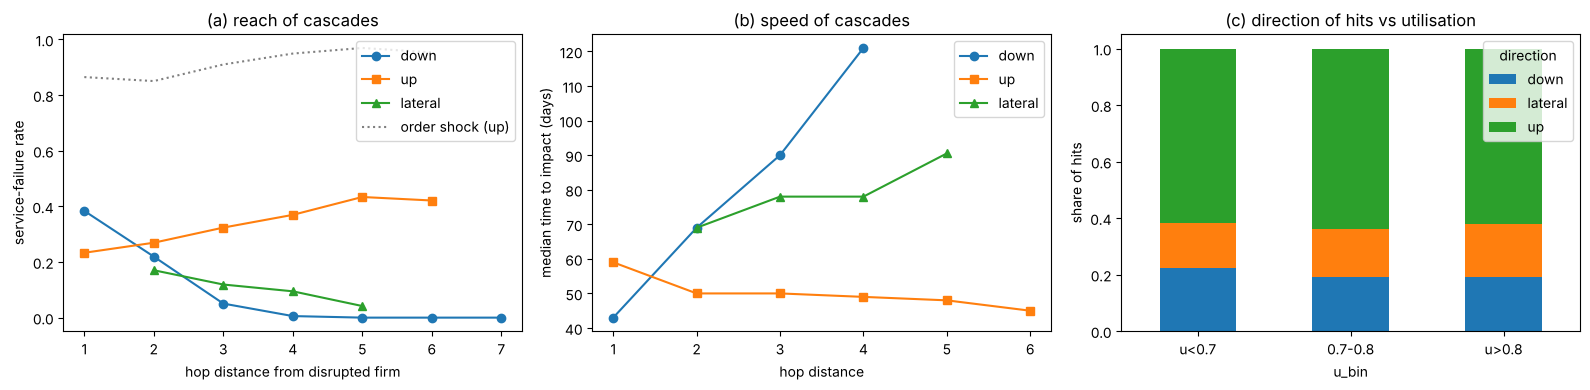

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hh = DF[DF.hop <= 10]
for d, sty in [("down", "-o"), ("up", "-s"), ("lateral", "-^")]:
    s = hh[hh.direction == d].groupby("hop").hit.mean()
    axes[0].plot(s.index, s.values, sty, label=d)
s = hh[hh.direction == "up"].groupby("hop").shock.mean()
axes[0].plot(s.index, s.values, ":", color="grey", label="order shock (up)")
axes[0].set(xlabel="hop distance from disrupted firm", ylabel="service-failure rate", title="(a) reach of cascades"); axes[0].legend()
for d, sty in [("down", "-o"), ("up", "-s"), ("lateral", "-^")]:
    s = hh[(hh.direction == d) & hh.hit].groupby("hop").tau.median()
    axes[1].plot(s.index, s.values, sty, label=d)
axes[1].set(xlabel="hop distance", ylabel="median time to impact (days)", title="(b) speed of cascades"); axes[1].legend()
DF["u_bin"] = pd.cut(DF.u, [0.55, 0.7, 0.8, 0.95], labels=["u<0.7", "0.7-0.8", "u>0.8"])
share = DF[DF.hit].groupby(["u_bin", "direction"], observed=True).size().unstack(fill_value=0)
(share.div(share.sum(1), axis=0)).plot(kind="bar", stacked=True, ax=axes[2], rot=0)
axes[2].set(ylabel="share of hits", title="(c) direction of hits vs utilisation")
plt.tight_layout(); plt.show()

### Cascade chart (one scenario)
Tier × day heatmap of extra unfilled orders (days of output, summed per tier) and the **cascade tree** built from causal parents.

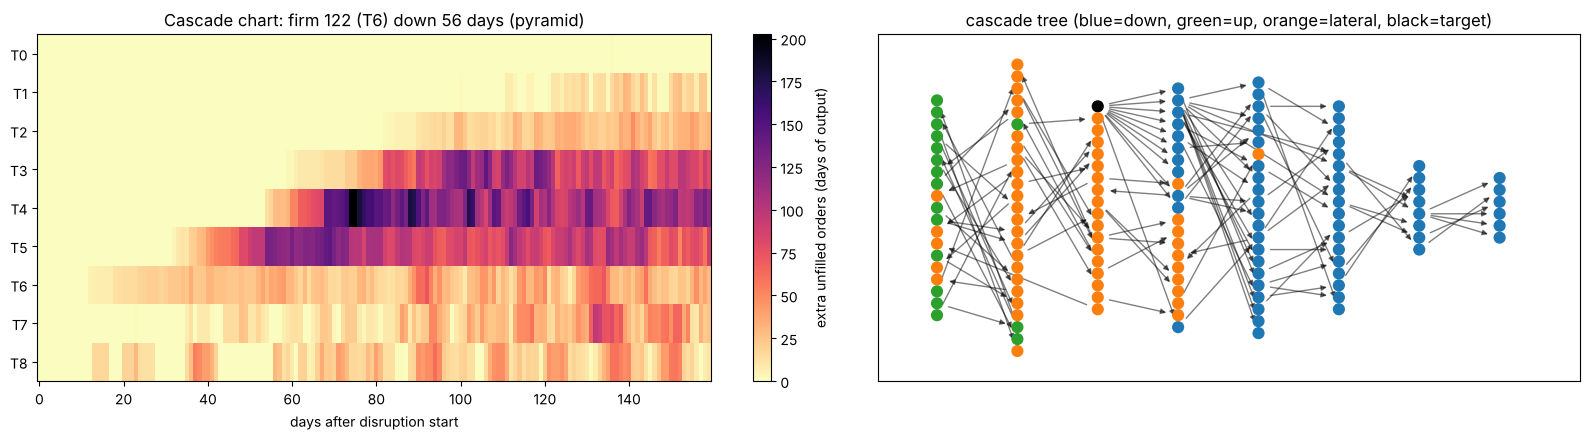

In [13]:
def pick_example():
    cand = [(k, r) for k, r in enumerate(RESULTS) if r["tier"] >= 6 and r["D"] == max(CFG["durations"])]
    return max(cand, key=lambda kr: (kr[1]["hit"].sum(), kr[1]["hit"][kr[1]["direction"] == "lateral"].sum()))


ex_id, ex = pick_example()
net = NETS[ex["net"]]
sim0 = warmup(net); c, _ = branch(sim0); d, _ = branch(sim0, target=ex["target"], D=float(ex["D"]))
deficit = np.clip((d["backlog"] - c["backlog"]) / net["thru"], 0, None)
heat = np.vstack([deficit[:, net["firm_tier"] == k].sum(1) for k in range(N_TIERS)])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw=dict(width_ratios=[1.2, 1]))
im = axes[0].imshow(heat, aspect="auto", cmap="magma_r", origin="upper")
axes[0].set(yticks=range(N_TIERS), yticklabels=[f"T{k}" for k in range(N_TIERS)], xlabel="days after disruption start",
            title=f"Cascade chart: firm {ex['target']} (T{ex['tier']}) down {ex['D']} days ({SPECS[ex['net']]['family']})")
plt.colorbar(im, ax=axes[0], label="extra unfilled orders (days of output)")
T = nx.DiGraph()
col = {"down": "tab:blue", "up": "tab:green", "lateral": "tab:orange", "self": "black"}
for f in np.flatnonzero(ex["hit"]):
    if ex["parent"][f] >= 0:
        T.add_edge(int(ex["parent"][f]), int(f))
T.add_node(ex["target"])
pos = {f: (net["firm_tier"][f] * -1.0, 0) for f in T}
for k in range(N_TIERS):
    fs = sorted([f for f in T if net["firm_tier"][f] == k])
    for r, f in enumerate(fs):
        pos[f] = (-k, r - (len(fs) - 1) / 2)
nx.draw_networkx_edges(T, pos, ax=axes[1], alpha=0.5, arrowsize=8)
nx.draw_networkx_nodes(T, pos, ax=axes[1], node_size=60, node_color=[col[ex["direction"][f]] for f in T])
axes[1].set_title("cascade tree (blue=down, green=up, orange=lateral, black=target)")
axes[1].set_xticks([-k for k in range(N_TIERS)]); axes[1].set_xticklabels([f"T{k}" for k in range(N_TIERS)])
axes[1].tick_params(left=False, labelleft=False)
plt.tight_layout(); plt.show()

### H1 — do diamonds cancel dual sourcing?
For every downstream firm we classify its **exposure** to the disrupted firm through its components:
- **single** — some component is single-sourced from the target or from a firm downstream of it;
- **diamond** — some component is dual-sourced but *every* source depends on the target (hidden concentration);
- **independent dual** — every exposed component has at least one source that does not depend on the target.

If H1 holds, diamond-exposed firms are hit about as often as single-sourced ones, and far more than independent-dual ones.

In [14]:
def exposure(net, target, desc):
    exp_ = np.array(["none"] * net["n_firms"], dtype=object)
    dep = desc | {target}
    for f in desc:
        cls = "none"
        for g in net["groups_of_firm"].get(f, []):
            srcs = net["g_src"][g]
            hit_srcs = [s for s in srcs if s in dep]
            if not hit_srcs:
                continue
            if len(srcs) == 1:
                cls = "single"; break
            if len(hit_srcs) == len(srcs):
                cls = "diamond" if cls != "single" else cls
            elif cls == "none":
                cls = "independent dual"
        exp_[f] = cls
    return exp_


exp_rows = []
for sc_id, r in enumerate(RESULTS):
    net = NETS[r["net"]]
    desc = nx.descendants(net["G"], r["target"])
    ex_ = exposure(net, r["target"], desc)
    for f in desc:
        exp_rows.append(dict(exposure=ex_[f], hit=bool(r["hit"][f]), D=r["D"], hop=int(r["hop"][f])))
EXP = pd.DataFrame(exp_rows)
h1 = EXP[EXP.exposure != "none"].groupby(["exposure"]).hit.agg(["mean", "size"]).rename(columns={"mean": "failure rate", "size": "n"})
h1["95% CI ±"] = 1.96 * np.sqrt(h1["failure rate"] * (1 - h1["failure rate"]) / h1["n"])
h1.round(3)

,failure rate,n,95% CI ±
exposure,,,
diamond,0.116,560,0.027
independent dual,0.089,2148,0.012
single,0.157,32768,0.004


### H2 — what do the topology rules miss?
Recall of the reachability rule and the cascade rule against the DES ground truth, by direction, and their timing error on correctly predicted downstream hits.

In [15]:
def rule_table(df):
    out = []
    for name, col in [("reachability", "reach_hit"), ("cascade rule", "rule_hit")]:
        for d in ["down", "up", "lateral", "all"]:
            s = df if d == "all" else df[df.direction == d]
            tp = (s[col] & s.hit).sum()
            out.append(dict(rule=name, direction=d, recall=tp / max(1, s.hit.sum()),
                            precision=tp / max(1, s[col].sum()), true_hits=int(s.hit.sum())))
    return pd.DataFrame(out).pivot(index="rule", columns="direction", values=["recall", "precision"]).round(3)


print("Share of all service failures that are NOT downstream (invisible to both rules by construction): %.3f"
      % (1 - DF[DF.hit].direction.eq("down").mean()))
rule_table(DF)

Share of all service failures that are NOT downstream (invisible to both rules by construction): 0.800


recall                     precision                    
direction       all   down lateral   up       all   down lateral   up
rule                                                                 
cascade rule  0.189  0.946     0.0  0.0     0.439  0.439     0.0  0.0
reachability  0.200  1.000     0.0  0.0     0.152  0.152     0.0  0.0

In [16]:
both = DF[(DF.direction == "down") & DF.hit & DF.rule_hit]
both_r = DF[(DF.direction == "down") & DF.hit & DF.reach_hit]
print("Timing error on correctly predicted downstream hits (days):")
pd.DataFrame({"cascade rule MAE": [np.nanmean(np.abs(both.rule_tau - both.tau))],
              "reachability MAE": [np.nanmean(np.abs(both_r.reach_tau - both_r.tau))],
              "n (cascade rule)": [len(both)]}).round(2)

Timing error on correctly predicted downstream hits (days):


,cascade rule MAE,reachability MAE,n (cascade rule)
0,26.59,57.8,5113


**Gate 3.** Cascades are non-trivial for a learner if the rules miss a substantial share of true hits (low recall overall, near zero off the downstream direction) or mistime them. If both rules matched the DES, a GNN would add nothing — check the two tables above before reading Stage 4.

## Stage 4 · GNN for cascade-risk prediction

**Input graph (per scenario).** Firm nodes; *sourcing-group* nodes, one per (buyer firm, component) — this is where the AND/OR logic lives; edges supplier → group (OR) and group → buyer (AND). Features: firm tier, utilisation, throughput, buffers, portfolio size, degrees, dual-sourcing share, lead times; group size, cover, closure flag; plus the **disruption signal** on the target (flag, duration).

**Models.**
- **AND/OR-GNN (proposed)** — each layer has the generic firm→firm channels *plus* the product-structure channels: sources → group with *sum + max* (OR), groups → buyer with *min + mean* (AND), and the reverse direction (buyer → group → sources) for upstream effects; residual updates; 8 layers.
- **Generic GNN** — GraphSAGE-style mean aggregation over firm→firm links in both directions; 8 layers; same width and training. It is the AND/OR-GNN **without** the product-structure channels, so the comparison is an ablation.
- **Feature MLP** — no message passing; gets the target relation explicitly (hop distance, direction, lead-time distance).
- **Rules** — reachability and cascade rule (Stage 3).

**Outputs.** Hit probability, time-to-impact (on hit firms), severity. **Splits by network:** train / val / test (same scale), and **big** (larger networks never seen).

In [17]:
def static_features(net):
    nF = net["n_firms"]; G = net["G"]
    ft = net["firm_tier"]
    feats = np.zeros((nF, N_TIERS + 9), dtype=np.float32)
    feats[np.arange(nF), ft] = 1
    in_lead = defaultdict(list)
    for (s, b), L in net["lead"].items():
        in_lead[b].append(L)
    for f in range(nF):
        gs = net["groups_of_firm"].get(f, [])
        feats[f, N_TIERS:] = [net["u_f"][f], np.log1p(net["thru"][f]) / 5, (net["fg_safety"][f] + LOT_DAYS / 2) / 10,
                              len(net["items_of"].get(f, [])) / 4, np.log1p(G.out_degree(f)) / 3, np.log1p(G.in_degree(f)) / 3,
                              np.mean([len(net["g_src"][g]) > 1 for g in gs]) if gs else 0.0,
                              (net["comp_safety"][f] + ORDER_DAYS / 2) / 10, np.mean(in_lead[f]) / 10 if in_lead[f] else 0.0]
    gfeat = np.array([[len(net["g_src"][g]) / 2, (net["comp_safety"][net["groups"][g][0]] + ORDER_DAYS / 2) / 10,
                       net["g_L"][g] / 10, float(g in net["closure_groups"])] for g in range(len(net["groups"]))], dtype=np.float32)
    sg_src, sg_grp, sg_L = [], [], []
    for g, srcs in enumerate(net["g_src"]):
        for s in srcs:
            sg_src.append(s); sg_grp.append(g); sg_L.append(net["lead"][(s, net["groups"][g][0])] / 10)
    ff = np.array(net["edges"]).T
    return dict(x=feats, gfeat=gfeat, g_buyer=np.array([g[0] for g in net["groups"]]), sg_src=np.array(sg_src),
                sg_grp=np.array(sg_grp), sg_L=np.array(sg_L, dtype=np.float32), ff=ff,
                ff_L=np.array([net["lead"][e] / 10 for e in net["edges"]], dtype=np.float32))


STATIC = [static_features(net) for net in NETS]
H_DAYS = CFG["horizon"]


def make_sample(r):
    st_ = STATIC[r["net"]]; nF = st_["x"].shape[0]
    dyn = np.zeros((nF, 2), dtype=np.float32)
    dyn[r["target"], 0] = 1; dyn[r["target"], 1] = r["D"] / max(CFG["durations"])
    dirs = r["direction"]
    rel = np.stack([r["hop"].clip(0, 12) / 12, dirs == "down", dirs == "up", dirs == "lateral"], 1).astype(np.float32)
    return dict(net=r["net"], x=np.hstack([st_["x"], dyn]), rel=rel, y_hit=r["hit"].astype(np.float32),
                y_tau=np.nan_to_num(r["tau"] / H_DAYS, nan=0).astype(np.float32),
                y_sev=np.log1p(r["sev"]).astype(np.float32), mask=(np.arange(nF) != r["target"]))


SAMPLES = [make_sample(r) for r in RESULTS]


def collate(batch):
    out = defaultdict(list); off_f = off_g = 0
    for s in batch:
        st_ = STATIC[s["net"]]; nF, nG = s["x"].shape[0], st_["gfeat"].shape[0]
        out["x"].append(s["x"]); out["rel"].append(s["rel"]); out["gfeat"].append(st_["gfeat"])
        out["g_buyer"].append(st_["g_buyer"] + off_f); out["sg_src"].append(st_["sg_src"] + off_f)
        out["sg_grp"].append(st_["sg_grp"] + off_g); out["sg_L"].append(st_["sg_L"])
        out["ff"].append(st_["ff"] + off_f); out["ff_L"].append(st_["ff_L"])
        for k in ["y_hit", "y_tau", "y_sev", "mask"]:
            out[k].append(s[k])
        off_f += nF; off_g += nG
    cat = {k: np.concatenate(v, axis=1 if k == "ff" else 0) for k, v in out.items()}
    t = {k: torch.as_tensor(v) for k, v in cat.items()}
    for k in ["g_buyer", "sg_src", "sg_grp", "ff"]:
        t[k] = t[k].long()
    t["mask"] = t["mask"].bool()
    t["nF"], t["nG"] = off_f, off_g
    return t


def scatter(src, idx, n, reduce):
    out = torch.zeros(n, src.shape[1], dtype=src.dtype)
    return out.scatter_reduce(0, idx.unsqueeze(1).expand_as(src), src, reduce=reduce, include_self=False)


def mlp(i, o, h=None):
    h = h or o
    return nn.Sequential(nn.Linear(i, h), nn.GELU(), nn.Linear(h, o))


class AndOrLayer(nn.Module):
    """Generic firm->firm channels (as SageLayer) PLUS the AND/OR channels through sourcing groups,
    so the comparison with SageLayer is a clean ablation of the product (BOM/sourcing) structure."""
    def __init__(self, H):
        super().__init__()
        self.m_sg = mlp(H + 1, H); self.g_up = mlp(3 * H + H, H)
        self.m_up = mlp(2 * H + 1, H); self.m_in = mlp(H + 1, H); self.m_out = mlp(H + 1, H)
        self.upd = mlp(7 * H, H); self.norm = nn.LayerNorm(H)

    def forward(self, h, hg0, b):
        s, d = b["ff"]
        mi = scatter(self.m_in(torch.cat([h[s], b["ff_L"][:, None]], 1)), d, b["nF"], "mean")
        mo = scatter(self.m_out(torch.cat([h[d], b["ff_L"][:, None]], 1)), s, b["nF"], "mean")
        m = self.m_sg(torch.cat([h[b["sg_src"]], b["sg_L"][:, None]], 1))
        g_or = torch.cat([scatter(m, b["sg_grp"], b["nG"], "sum"), scatter(m, b["sg_grp"], b["nG"], "amax")], 1)   # OR
        hg = self.g_up(torch.cat([g_or, h[b["g_buyer"]], hg0], 1))
        f_and = torch.cat([scatter(hg, b["g_buyer"], b["nF"], "amin"), scatter(hg, b["g_buyer"], b["nF"], "mean")], 1)  # AND
        up = self.m_up(torch.cat([hg[b["sg_grp"]], h[b["sg_src"]], b["sg_L"][:, None]], 1))
        f_up = torch.cat([scatter(up, b["sg_src"], b["nF"], "sum"), scatter(up, b["sg_src"], b["nF"], "amax")], 1)
        return self.norm(h + self.upd(torch.cat([h, mi, mo, f_and, f_up], 1)))


class SageLayer(nn.Module):
    def __init__(self, H):
        super().__init__()
        self.m_in = mlp(H + 1, H); self.m_out = mlp(H + 1, H); self.upd = mlp(3 * H, H); self.norm = nn.LayerNorm(H)

    def forward(self, h, hg0, b):
        s, d = b["ff"]
        mi = scatter(self.m_in(torch.cat([h[s], b["ff_L"][:, None]], 1)), d, b["nF"], "mean")
        mo = scatter(self.m_out(torch.cat([h[d], b["ff_L"][:, None]], 1)), s, b["nF"], "mean")
        return self.norm(h + self.upd(torch.cat([h, mi, mo], 1)))


class CascadeNet(nn.Module):
    def __init__(self, kind, d_in, H, layers=8):
        super().__init__()
        self.kind = kind
        extra = 4 if kind == "mlp" else 0
        self.enc = mlp(d_in + extra, H); self.genc = mlp(4, H)
        L = {"andor": AndOrLayer, "sage": SageLayer}.get(kind)
        self.layers = nn.ModuleList([L(H) for _ in range(layers)]) if L else nn.ModuleList()
        self.head = mlp(H, 3)

    def forward(self, b):
        x = torch.cat([b["x"], b["rel"]], 1) if self.kind == "mlp" else b["x"]
        h, hg0 = self.enc(x), self.genc(b["gfeat"])
        for layer in self.layers:
            h = layer(h, hg0, b)
        o = self.head(h)
        return o[:, 0], torch.sigmoid(o[:, 1]), F.softplus(o[:, 2])


def loss_fn(out, b, pos_w):
    logit, tau, sev = out; m = b["mask"]
    l_hit = F.binary_cross_entropy_with_logits(logit[m], b["y_hit"][m], pos_weight=pos_w)
    hm = m & (b["y_hit"] > 0)
    l_tau = F.smooth_l1_loss(tau[hm], b["y_tau"][hm], beta=0.05) if hm.any() else 0.0
    l_sev = F.smooth_l1_loss(sev[m], b["y_sev"][m])
    return l_hit + 2.0 * l_tau + 0.5 * l_sev


SPLIT_IDX = {sp: [k for k, s in enumerate(SAMPLES) if SPECS[s["net"]]["split"] == sp] for sp in ["train", "val", "test", "big"]}
print({k: len(v) for k, v in SPLIT_IDX.items()})


def predict(model, idx, bs=32):
    model.eval(); res = defaultdict(list)
    with torch.no_grad():
        for k in range(0, len(idx), bs):
            b = collate([SAMPLES[j] for j in idx[k:k + bs]])
            logit, tau, sev = model(b)
            res["p"].append(torch.sigmoid(logit).numpy()); res["tau"].append(tau.numpy() * H_DAYS)
            res["mask"].append(b["mask"].numpy())
    return {k: np.concatenate(v) for k, v in res.items()}


def train(kind, epochs=CFG["epochs"], bs=16, lr=2e-3, seed=0):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = CascadeNet(kind, SAMPLES[0]["x"].shape[1], CFG["hidden"])
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    ytr = np.concatenate([SAMPLES[j]["y_hit"][SAMPLES[j]["mask"]] for j in SPLIT_IDX["train"]])
    pos_w = torch.tensor(min(20.0, (1 - ytr.mean()) / max(ytr.mean(), 1e-3)))
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        order = rng.permutation(SPLIT_IDX["train"])
        for k in range(0, len(order), bs):
            b = collate([SAMPLES[j] for j in order[k:k + bs]])
            loss = loss_fn(model(b), b, pos_w)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        sched.step()
        pv = predict(model, SPLIT_IDX["val"])
        yv = np.concatenate([SAMPLES[j]["y_hit"] for j in SPLIT_IDX["val"]])[pv["mask"]]
        ap = average_precision_score(yv, pv["p"][pv["mask"]]) if yv.any() else 0
        if ap > best:
            best, best_state = ap, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, best


t0 = time.time()
MODELS = {}
for kind in ["andor", "sage", "mlp"]:
    MODELS[kind], ap = train(kind)
    print(f"{kind:6s} best val AUPRC {ap:.3f}  ({time.time()-t0:.0f}s)")

{'train': 576, 'val': 96, 'test': 96, 'big': 288}


andor  best val AUPRC 0.748  (487s)


sage   best val AUPRC 0.581  (636s)


mlp    best val AUPRC 0.499  (640s)


### Results (H3)
AUPRC (scores) and F1 (threshold tuned on validation) for the learned models; precision/recall-based F1 for the rules. τ error is the MAE in days on true hits that the model also predicts as hits. Reported on the **test** networks (same scale, unseen) and the **big** networks (larger, unseen).

In [18]:
HOP_BINS = [(1, 1), (2, 2), (3, 3), (4, 4), (5, 5), (6, 7), (8, 98)]


def evaluate(split):
    idx = SPLIT_IDX[split]
    y = np.concatenate([SAMPLES[j]["y_hit"] for j in idx]).astype(bool)
    tau_true = np.concatenate([RESULTS[j]["tau"] for j in idx])
    mask = np.concatenate([SAMPLES[j]["mask"] for j in idx])
    direction = np.concatenate([RESULTS[j]["direction"] for j in idx])
    hop = np.concatenate([RESULTS[j]["hop"] for j in idx])
    preds = {}
    for kind, model in MODELS.items():
        pv = predict(model, SPLIT_IDX["val"]); yv = np.concatenate([SAMPLES[j]["y_hit"] for j in SPLIT_IDX["val"]])
        ths = np.linspace(0.05, 0.95, 19)
        th = ths[np.argmax([f1_score(yv[pv["mask"]] > 0, pv["p"][pv["mask"]] > t) for t in ths])]
        p = predict(model, idx)
        preds[kind] = dict(score=p["p"], hit=p["p"] > th, tau=p["tau"])
    preds["cascade rule"] = dict(score=None, hit=np.concatenate([RESULTS[j]["rule_hit"] for j in idx]),
                                 tau=np.concatenate([RESULTS[j]["rule_tau"] for j in idx]))
    preds["reachability"] = dict(score=None, hit=np.concatenate([RESULTS[j]["reach_hit"] for j in idx]),
                                 tau=np.concatenate([RESULTS[j]["reach_tau"] for j in idx]))
    rows, by_hop, by_dir = [], [], []
    for name, pr in preds.items():
        m = mask
        both = m & y & pr["hit"]
        rows.append(dict(model=name, AUPRC=average_precision_score(y[m], pr["score"][m]) if pr["score"] is not None else np.nan,
                         F1=f1_score(y[m], pr["hit"][m]), precision=precision_score(y[m], pr["hit"][m], zero_division=0),
                         recall=recall_score(y[m], pr["hit"][m]), tau_MAE_days=np.nanmean(np.abs(pr["tau"][both] - tau_true[both]))))
        for lo, hi in HOP_BINS:
            sel = m & (hop >= lo) & (hop <= hi)
            if y[sel].sum() >= 5:
                by_hop.append(dict(model=name, hop=lo, F1=f1_score(y[sel], pr["hit"][sel])))
        for d in ["down", "up", "lateral"]:
            sel = m & (direction == d)
            if y[sel].sum() >= 5:
                by_dir.append(dict(model=name, direction=d, recall=recall_score(y[sel], pr["hit"][sel]),
                                   F1=f1_score(y[sel], pr["hit"][sel])))
    return pd.DataFrame(rows).set_index("model").round(3), pd.DataFrame(by_hop), pd.DataFrame(by_dir)


TEST, TEST_HOP, TEST_DIR = evaluate("test")
BIG, BIG_HOP, BIG_DIR = evaluate("big")
print("TEST (unseen networks, same scale)"); display(TEST)
print("BIG (unseen, larger networks)"); display(BIG)

TEST (unseen networks, same scale)


,AUPRC,F1,precision,recall,tau_MAE_days
model,,,,,
andor,0.713,0.629,0.518,0.799,18.414
sage,0.459,0.552,0.462,0.687,20.555
mlp,0.439,0.444,0.306,0.809,23.190
cascade rule,NaN,0.310,0.445,0.238,21.378
reachability,NaN,0.178,0.141,0.241,51.842


BIG (unseen, larger networks)


,AUPRC,F1,precision,recall,tau_MAE_days
model,,,,,
andor,0.680,0.632,0.595,0.675,22.819
sage,0.537,0.565,0.525,0.610,25.098
mlp,0.498,0.477,0.337,0.815,25.428
cascade rule,NaN,0.235,0.409,0.165,29.959
reachability,NaN,0.153,0.136,0.175,61.860


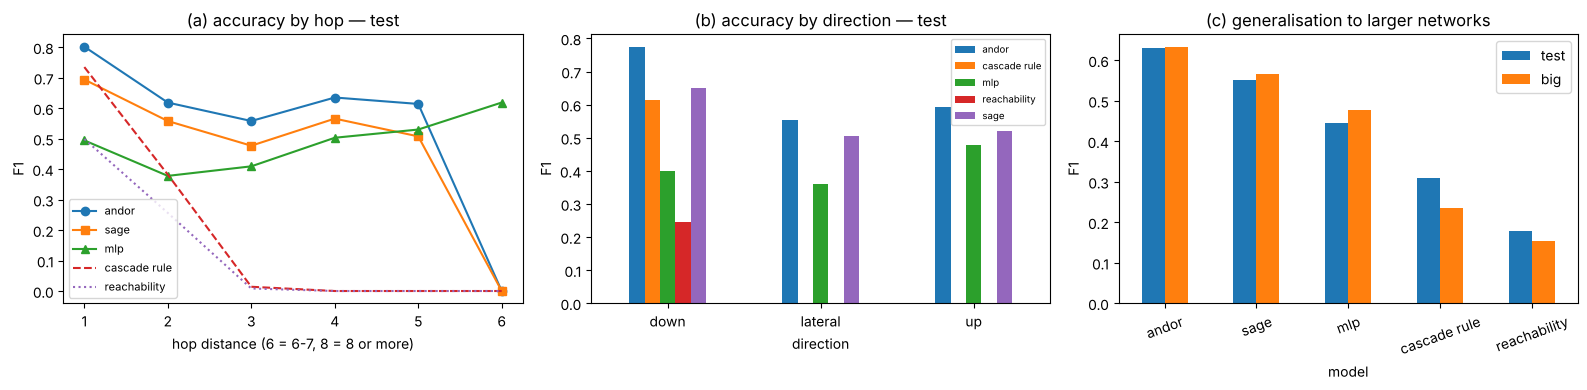

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, sty in [("andor", "-o"), ("sage", "-s"), ("mlp", "-^"), ("cascade rule", "--"), ("reachability", ":")]:
    s = TEST_HOP[TEST_HOP.model == name]
    axes[0].plot(s.hop, s.F1, sty, label=name)
axes[0].set(xlabel="hop distance (6 = 6-7, 8 = 8 or more)", ylabel="F1", title="(a) accuracy by hop — test"); axes[0].legend(fontsize=8)
TEST_DIR.pivot(index="direction", columns="model", values="F1").plot(kind="bar", ax=axes[1], rot=0)
axes[1].set(ylabel="F1", title="(b) accuracy by direction — test"); axes[1].legend(fontsize=7)
comp = pd.DataFrame({"test": TEST.F1, "big": BIG.F1})
comp.plot(kind="bar", ax=axes[2], rot=20)
axes[2].set(ylabel="F1", title="(c) generalisation to larger networks")
plt.tight_layout(); plt.show()

### Speed
One GNN forward pass over a scenario vs one DES run.

In [20]:
j = SPLIT_IDX["test"][0]; b = collate([SAMPLES[j]])
t0 = time.time()
for _ in range(20):
    with torch.no_grad():
        MODELS["andor"](b)
gnn_ms = (time.time() - t0) / 20 * 1000
net = NETS[SAMPLES[j]["net"]]; sim0 = warmup(net)
t0 = time.time(); branch(sim0, target=RESULTS[j]["target"], D=float(RESULTS[j]["D"])); des_ms = (time.time() - t0) * 1000
print(f"GNN inference {gnn_ms:.1f} ms per scenario vs DES {des_ms:.0f} ms per scenario (one network of {net['n_firms']} firms)")

GNN inference 20.5 ms per scenario vs DES 135 ms per scenario (one network of 102 firms)


## Summary for the paper
The cells below collect the numbers each hypothesis rests on. Interpret them **as they come out** — in `quick` mode the networks are small and few, so the numbers are a pipeline check, not results.

- **Gate 1 / atlas:** structural table, triad z-scores, control-response correlations.
- **Gate 2:** validation printout.
- **H1:** hit-rate by direction and utilisation; diamond vs single vs independent-dual exposure.
- **H2:** rule recall/precision by direction; timing error.
- **H3:** model table on test and big networks; F1 by hop and direction.

In [21]:
summary_rows = {
    "networks": len(NETS), "scenarios": len(RESULTS), "firm-scenario rows": len(DF),
    "service-failure rate": round(DF.hit.mean(), 3),
    "order-shock rate": round(DF.shock.mean(), 3),
    "share of failures not downstream": round(1 - DF[DF.hit].direction.eq("down").mean(), 3),
    "cascade-rule recall (all failures)": round((DF.rule_hit & DF.hit).sum() / DF.hit.sum(), 3),
}
for e in ["single", "diamond", "independent dual"]:
    if e in h1.index:
        summary_rows[f"H1 failure rate, {e}"] = round(h1.loc[e, "failure rate"], 3)
for m in TEST.index:
    summary_rows[f"H3 test F1, {m}"] = TEST.loc[m, "F1"]
    summary_rows[f"H3 big F1, {m}"] = BIG.loc[m, "F1"]
pd.Series(summary_rows, name=MODE).to_frame()

,quick
networks,33.000
scenarios,1056.000
firm-scenario rows,121632.000
service-failure rate,0.222
order-shock rate,0.541
share of failures not downstream,0.800
cascade-rule recall (all failures),0.189
"H1 failure rate, single",0.157
"H1 failure rate, diamond",0.116
"H1 failure rate, independent dual",0.089
